In [3]:
# from sympy import Matrix, symbols, log, exp, simplify, Mul, Pow
import jax
import jax.numpy as jnp
import numpy as np
from tca_openflux import TCA_OpenFLux, objective_wssr, objective_clr_wssr, free_parameters
from emu_example import closure, clr_func, clr_inv_func, calc_ci

import optimistix
import matplotlib.pyplot as plt

In [4]:
v_free = {"v8": 0.215, "v1": 1, "v19": 0.05, "v20": 0.03, "v16": 0.07, "v17": 0.23, "v18": 0.12, "v2": 0.201, "v9": 0.296}
fixed = jnp.array([v_free["v1"], v_free["v16"], v_free["v17"], v_free["v18"], v_free["v19"], v_free["v20"]])
# parameters = jnp.array([v8,v19,v20,v16,v17,v18,v2,v9])
parameters = jnp.array([v_free["v8"],v_free["v2"],v_free["v9"]])
data = TCA_OpenFLux(parameters=parameters, fixed=fixed)

# Simulations

In [5]:
rng = np.random.default_rng(seed=1234)
key = jax.random.PRNGKey(1234)
sims = 1000

total_mol = 1e5
total_isos = jax.tree.map(lambda x: x * total_mol, data)
cv = 0.2
norm_sigma_cv = jax.tree.map(lambda x: x * cv, total_isos)

key, key_sim = jax.random.split(key)
norm_sim = jax.tree.map(
    lambda mean, sigma: mean + sigma * jax.random.normal(key_sim, (sims, mean.shape[0])),
    total_isos,
    norm_sigma_cv,
)

In [6]:
# Simulated reads closed to 1
iso_proportions = jax.tree.map(
    lambda mat: closure(mat),
    norm_sim,
)

# Check that all sum to 1
jax.tree.map(
    lambda x: jnp.all(jnp.isclose(jnp.sum(x, axis=-1), 1.0, rtol=1e-10, atol=1e-10)),
    iso_proportions
)

{'aspx_1234': Array(True, dtype=bool),
 'lysx_123456': Array(True, dtype=bool),
 'suc_1234': Array(True, dtype=bool),
 'valx_12345': Array(True, dtype=bool)}

In [7]:
mean_sim = jax.tree.map(
    lambda x: jnp.mean(x, axis=0),  # mean over isotopolouges
    iso_proportions
)

std_sim = jax.tree.map(
    lambda x: jnp.std(x, axis=0),  # standard deviation over isotopolouges
    iso_proportions
)

D_sim = jax.tree.map(
    lambda x: jnp.diag(x), 
    std_sim
)

In [8]:
solver = optimistix.BFGS(
    rtol=1e-12, atol=1e-12, verbose=frozenset({"step"})
)

In [9]:
# initial_guess = jnp.array([0.043 , 0.01  , 0.006 , 0.014 , 0.046 , 0.024 , 0.0402, 0.0592])
initial_guess = jnp.array([1, 1, 1]) # v8, v2, v9

In [10]:
result_optimistix = optimistix.minimise(objective_wssr, y0=initial_guess, args=(mean_sim, D_sim, fixed), solver=solver, max_steps=10000)

In [11]:
calc_ci(result_optimistix)

{'params': Array([0.22399349, 0.20240499, 0.30363819], dtype=float64),
 'standard_errors': Array([0.94859567, 0.10207766, 0.64257102], dtype=float64),
 'ci_bounds': Array([[-1.63521987,  2.08320685],
        [ 0.00233646,  0.40247352],
        [-0.95577786,  1.56305425]], dtype=float64)}

# CLR transformed

In [12]:
iso_clr = jax.tree.map(
    lambda x: clr_func(x),
    iso_proportions
)

# Check that all sum to 0
jax.tree.map(
    lambda x: jnp.all(jnp.isclose(jnp.sum(x, axis=-1), 0.0, rtol=1e-10, atol=1e-10)),
    iso_clr
)

{'aspx_1234': Array(True, dtype=bool),
 'lysx_123456': Array(True, dtype=bool),
 'suc_1234': Array(True, dtype=bool),
 'valx_12345': Array(True, dtype=bool)}

In [13]:
mean_clr = jax.tree.map(
    lambda x: jnp.mean(x, axis=0),  # mean over bins
    iso_clr
)

std_clr = jax.tree.map(
    lambda x: jnp.std(x, axis=0),  # mean over isotopolouges
    iso_clr
)

D_clr = jax.tree.map(
    lambda x: jnp.diag(x), 
    std_clr
)

In [14]:
mean_clr_inv = jax.tree.map(
    lambda x: clr_inv_func(x),
    mean_clr
)

In [15]:
result_optimistix_clr  = optimistix.minimise(objective_clr_wssr, y0=initial_guess, args=(mean_clr, D_clr, fixed), solver=solver, max_steps=10000)

In [16]:
calc_ci(result_optimistix_clr)

{'params': Array([0.21283379, 0.20105222, 0.29512406], dtype=float64),
 'standard_errors': Array([0.32225672, 0.02331375, 0.12678905], dtype=float64),
 'ci_bounds': Array([[-0.41877777,  0.84444535],
        [ 0.15535811,  0.24674633],
        [ 0.04662208,  0.54362604]], dtype=float64)}

In [17]:
print("True parameters: ", parameters)
print("Euclidean estimated parameters: ", result_optimistix.value)
print("CLR transformed estimated parameters: ", result_optimistix_clr.value)

True parameters:  [0.215 0.201 0.296]
Euclidean estimated parameters:  [0.22399349 0.20240499 0.30363819]
CLR transformed estimated parameters:  [0.21283379 0.20105222 0.29512406]


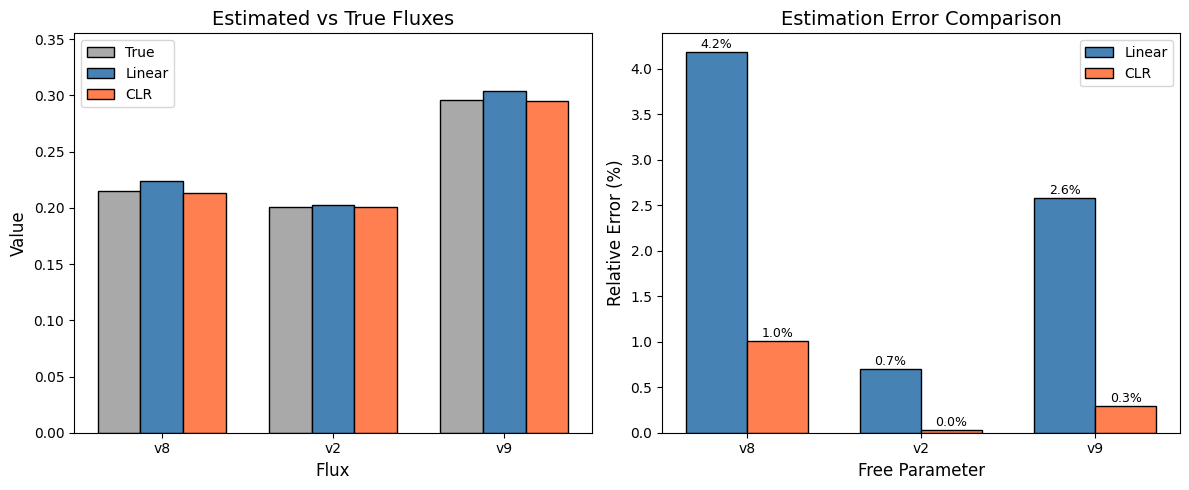

In [ ]:
# Comparison plot: Estimated fluxes vs True fluxes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: Bar chart comparing all fluxes
flux_labels = ['v8', 'v2', 'v9']
x = np.arange(len(flux_labels))
width = 0.25

v_true = parameters
v_est = result_optimistix.value
v_clr = result_optimistix_clr.value

bars1 = axes[0].bar(x - width, v_true, width, label='True', color='darkgray', edgecolor='black')
bars2 = axes[0].bar(x, v_est, width, label='Linear', color='steelblue', edgecolor='black')
bars3 = axes[0].bar(x + width, v_clr, width, label='CLR', color='coral', edgecolor='black')

axes[0].set_xlabel('Flux', fontsize=12)
axes[0].set_ylabel('Value', fontsize=12)
axes[0].set_title('Estimated vs True Fluxes', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels(flux_labels)
axes[0].legend(fontsize=10)
axes[0].set_ylim(0, max(v_true)*1.2)

# Right: Relative error (%) for free parameters only
free_params = ['v8', 'v2', 'v9']
true_vals = v_true
linear_vals = v_est
clr_vals = v_clr

rel_error_linear = 100 * np.abs(linear_vals - true_vals) / true_vals
rel_error_clr = 100 * np.abs(clr_vals - true_vals) / true_vals

x2 = np.arange(len(free_params))
width2 = 0.35

bars4 = axes[1].bar(x2 - width2/2, rel_error_linear, width2, label='Linear', color='steelblue', edgecolor='black')
bars5 = axes[1].bar(x2 + width2/2, rel_error_clr, width2, label='CLR', color='coral', edgecolor='black')

axes[1].set_xlabel('Free Parameter', fontsize=12)
axes[1].set_ylabel('Relative Error (%)', fontsize=12)
axes[1].set_title('Estimation Error Comparison', fontsize=14)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(free_params)
axes[1].legend(fontsize=10)

# Add value labels on bars
for bar in bars4:
    height = bar.get_height()
    axes[1].annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)
for bar in bars5:
    height = bar.get_height()
    axes[1].annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [27]:
print("true fluxes: ", free_parameters(parameters, fixed))

true fluxes:  [0.215 1.    0.05  0.03  0.07  0.23  0.12  0.201 0.296 0.621 0.621 0.621
 0.592 1.213 0.296 1.509 1.735 5.561 0.475 0.807]


In [28]:
print("estimated fluxes: ", np.round(free_parameters(result_optimistix.value, fixed),3))

estimated fluxes:  [0.224 1.    0.05  0.03  0.07  0.23  0.12  0.202 0.304 0.622 0.622 0.622
 0.595 1.217 0.297 1.515 1.742 5.577 0.481 0.819]


In [29]:
print("estimated fluxes clr: ", np.round(free_parameters(result_optimistix_clr.value, fixed),3))

estimated fluxes clr:  [0.213 1.    0.05  0.03  0.07  0.23  0.12  0.201 0.295 0.621 0.621 0.621
 0.592 1.213 0.296 1.509 1.735 5.563 0.474 0.805]
